# Email Marketing Experiment: A/B Testing, Uplift Modeling, and Segmentation

## Question
A retailer ran a randomized email experiment on 64,000 recent customers. One third received an email
featuring **men's** merchandise, one third received an email featuring **women's** merchandise, and one
third received **no email** (control). Visits, purchases, and spending were tracked for two weeks.

The marketing team wants to know:
1. **Did the emails work?** Which creative (men's vs. women's) performed better, and are the results statistically reliable?
2. **Who responds?** Can we predict which customers will visit after an email (propensity model)?
3. **Who is persuadable?** Which customers visit *because of* the email, rather than customers who would have visited anyway (uplift model)?
4. **Who should get which email?** If we could only email 10,000 customers, who should they be?

## Methods
A/B testing and RCT analysis · two-proportion z-tests, Welch t-tests, bootstrap CIs, multiple-testing correction ·
power analysis · segment tests with interaction regressions · propensity models (logistic regression, decision tree,
random forest, gradient boosting, neural network) · uplift modeling (T-learner, uplift decision tree) · Qini curves ·
targeting policy evaluation

**Data:** Kevin Hillstrom's *MineThatData E-Mail Analytics and Data Mining Challenge* (2008).

## Set up

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

SEED = 42
DATA_PATH = Path("Hillstrom Email Marketing dataset.csv")
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)
COLORS = {"Control": "#a0aec0", "Mens": "#2b6cb0", "Womens": "#d53f8c"}

## Load data \& Data Cleaning

Each row is a customer. Features describe the customer before the campaign; `segment` is the randomly
assigned email; `visit`, `conversion`, and `spend` are outcomes in the two weeks after.

In [5]:
df = pd.read_csv(DATA_PATH)
print(f"{df.shape[0]:,} customers x {df.shape[1]} columns")
df.head()

64,000 customers x 12 columns


,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend
0,10,2) $100 - $200,142.44,1,0,Surburban,0,Phone,Womens E-Mail,0,0,0.0
1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0
2,7,2) $100 - $200,180.65,0,1,Surburban,1,Web,Womens E-Mail,0,0,0.0
3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0
4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0


In [ ]:
# Check for missing values
print("Missing values per column:")
print(df.isna().sum().to_string(), "\n")

# List the unique categories in each column to check if there are any unexpected values or misspealling
for col in ["zip_code", "channel", "segment", "history_segment"]:
    print(f"{col}: {sorted(df[col].unique())}")

Missing values per column:
recency            0
history_segment    0
history            0
mens               0
womens             0
zip_code           0
newbie             0
channel            0
segment            0
visit              0
conversion         0
spend              0 

zip_code: ['Rural', 'Surburban', 'Urban']
channel: ['Multichannel', 'Phone', 'Web']
segment: ['Mens E-Mail', 'No E-Mail', 'Womens E-Mail']
history_segment: ['1) $0 - $100', '2) $100 - $200', '3) $200 - $350', '4) $350 - $500', '5) $500 - $750', '6) $750 - $1,000', '7) $1,000 +']


`zip_code` contains a misspelled category (`Surburban`), which I correct. I also check that the outcomes are
logically consistent (anyone who spent money must have converted, and anyone who converted must have visited)
and that values fall in valid ranges.

In [ ]:
df["zip_code"] = df["zip_code"].replace({"Surburban": "Suburban"})

# Check to see if there are any rows that violate the expected data constraints
checks = {
    "spend > 0 but no conversion": ((df.spend > 0) & (df.conversion == 0)).sum(),
    "conversion but no visit": ((df.conversion == 1) & (df.visit == 0)).sum(),
    "recency outside 1-12 months": (~df.recency.between(1, 12)).sum(),
    "non-positive purchase history": (df.history <= 0).sum(),
    "bought neither mens nor womens": ((df.mens == 0) & (df.womens == 0)).sum(),
}
pd.Series(checks, name="rows failing check").to_frame()

,rows failing check
spend > 0 but no conversion,0
conversion but no visit,0
recency outside 1-12 months,0
non-positive purchase history,0
bought neither mens nor womens,0


In [8]:
# Identical rows: the data has no customer ID, so different customers can share the same values.
print(f"Identical rows: {df.duplicated().sum():,}  -> kept, since they represent different customers")

# shows summary statistics for the key numeric variables
df["arm"] = df["segment"].map({"No E-Mail": "Control", "Mens E-Mail": "Mens", "Womens E-Mail": "Womens"})
df["purchase_history"] = np.select(
    [(df.mens == 1) & (df.womens == 1), df.mens == 1], ["Both", "Mens only"], default="Womens only")
df["recency_group"] = pd.cut(df.recency, [0, 3, 6, 9, 12], labels=["1-3 mo", "4-6 mo", "7-9 mo", "10-12 mo"])
df["log_history"] = np.log(df.history)
df["newbie_label"] = df.newbie.map({1: "New (last 12 mo)", 0: "Existing"})
df[["recency", "history", "visit", "conversion", "spend"]].describe().round(3)

Identical rows: 6,562  -> kept, since they represent different customers


,recency,history,visit,conversion,spend
count,64000.000,64000.000,64000.000,64000.000,64000.000
mean,5.764,242.086,0.147,0.009,1.051
std,3.508,256.159,0.354,0.095,15.036
min,1.000,29.990,0.000,0.000,0.000
25%,2.000,64.660,0.000,0.000,0.000
50%,6.000,158.110,0.000,0.000,0.000
75%,9.000,325.657,0.000,0.000,0.000
max,12.000,3345.930,1.000,1.000,499.000


## EDA

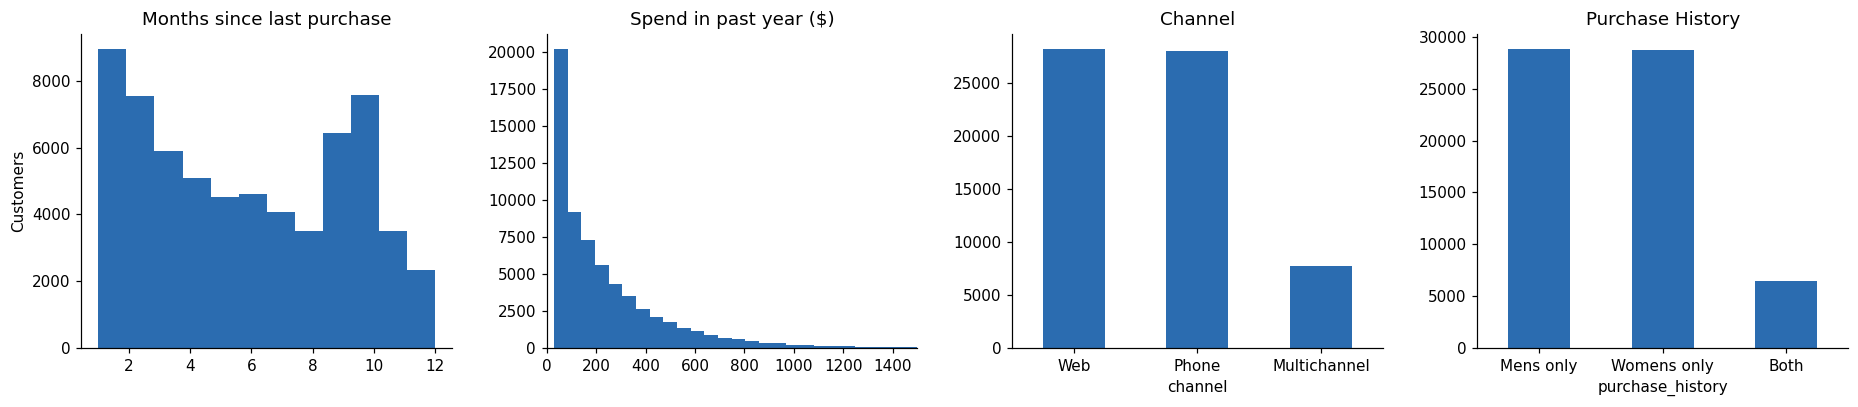

,customers,visit_rate,conversion_rate,spend_per_customer
arm,,,,
Control,21306,0.1062,0.0057,0.6528
Mens,21307,0.1828,0.0125,1.4226
Womens,21387,0.1514,0.0088,1.0772


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
axes[0].hist(df.recency, bins=12, color="#2b6cb0"); axes[0].set(title="Months since last purchase", ylabel="Customers")
axes[1].hist(df.history, bins=60, color="#2b6cb0"); axes[1].set(title="Spend in past year ($)", xlim=(0, 1500))
for ax, col in zip(axes[2:], ["channel", "purchase_history"]):
    df[col].value_counts().plot.bar(ax=ax, color="#2b6cb0", rot=0); ax.set(title=col.replace("_", " ").title())
plt.tight_layout(); plt.show()

summary = df.groupby("arm").agg(customers=("visit", "size"), visit_rate=("visit", "mean"),
                                conversion_rate=("conversion", "mean"), spend_per_customer=("spend", "mean"))
summary.round(4)

## Check to see if the experiment is valid 

Before trusting any results, two checks:
- **Sample ratio mismatch (SRM):** customers should be split about 1/3 per group. A chi-square test checks this.
- **Covariate balance:** randomization should make groups look alike before the campaign. I use the
  standardized mean difference (SMD); values below 0.1 are considered balanced.

In [10]:
counts = df.arm.value_counts().sort_index()
chi2, p_srm = stats.chisquare(counts, f_exp=[len(df) / 3] * 3)
print(counts.to_string())
print(f"\nSRM chi-square = {chi2:.2f}, p = {p_srm:.3f}  ->  {'no evidence of' if p_srm > 0.01 else 'POSSIBLE'} sample ratio mismatch")

arm
Control    21306
Mens       21307
Womens     21387

SRM chi-square = 0.20, p = 0.904  ->  no evidence of sample ratio mismatch


In [11]:
X_bal = pd.get_dummies(df[["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]], dtype=float)

def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

balance = pd.DataFrame({
    f"SMD {arm} vs Control": [smd(X_bal.loc[df.arm == arm, c], X_bal.loc[df.arm == "Control", c]) for c in X_bal]
    for arm in ["Mens", "Womens"]}, index=X_bal.columns).round(3)
print(f"Largest |SMD|: {balance.abs().max().max():.3f}  (threshold 0.1)")
balance

Largest |SMD|: 0.014  (threshold 0.1)


,SMD Mens vs Control,SMD Womens vs Control
recency,0.007,0.005
history,0.008,0.007
mens,-0.005,-0.009
womens,0.008,0.005
newbie,-0.001,0.003
zip_code_Rural,0.014,0.004
zip_code_Suburban,-0.012,-0.001
zip_code_Urban,0.002,-0.002
channel_Multichannel,-0.004,-0.005
channel_Phone,-0.008,0.009


Groups are the expected size and well balanced on every pre-campaign characteristic, so differences in outcomes can be attributed to the emails.

 A/B test results
Three comparisons on three outcomes:
- **Men's email vs. control** and **Women's email vs. control:** did each email work?
- **Men's vs. Women's email:** a **creative test** between the two versions.

Binary outcomes (visit, conversion) use a **two-proportion z-test**. Spend per customer is very skewed
(most customers spend $0), so I use a **Welch t-test** plus a **bootstrap confidence interval**. Running 9 tests
inflates the chance of a false positive, so p-values are adjusted with the **Holm** correction.

In [12]:
rng = np.random.default_rng(SEED)

def compare(arm_a, arm_b, outcome, n_boot=2000):
    a, b = df.loc[df.arm == arm_a, outcome].to_numpy(), df.loc[df.arm == arm_b, outcome].to_numpy()
    diff = a.mean() - b.mean()
    if outcome in ("visit", "conversion"):
        _, p = proportions_ztest([a.sum(), b.sum()], [len(a), len(b)])
        lo, hi = confint_proportions_2indep(a.sum(), len(a), b.sum(), len(b), method="wald")
    else:
        p = stats.ttest_ind(a, b, equal_var=False).pvalue
        boots = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(n_boot)]
        lo, hi = np.percentile(boots, [2.5, 97.5])
    return {"comparison": f"{arm_a} vs {arm_b}", "outcome": outcome, "rate_a": a.mean(), "rate_b": b.mean(),
            "difference": diff, "ci_low": lo, "ci_high": hi, "relative_lift": diff / b.mean(), "p_value": p}

tests = pd.DataFrame([compare(a, b, o)
                      for a, b in [("Mens", "Control"), ("Womens", "Control"), ("Mens", "Womens")]
                      for o in ["visit", "conversion", "spend"]])
tests["p_holm"] = multipletests(tests.p_value, method="holm")[1]
tests["significant"] = tests.p_holm < 0.05
tests.round(4)

,comparison,outcome,rate_a,rate_b,difference,ci_low,ci_high,relative_lift,p_value,p_holm,significant
0,Mens vs Control,visit,0.1828,0.1062,0.0766,0.0700,0.0832,0.7214,0.0000,0.0000,True
1,Mens vs Control,conversion,0.0125,0.0057,0.0068,0.0050,0.0086,1.1884,0.0000,0.0000,True
2,Mens vs Control,spend,1.4226,0.6528,0.7698,0.4840,1.0517,1.1793,0.0000,0.0000,True
3,Womens vs Control,visit,0.1514,0.1062,0.0452,0.0389,0.0516,0.4261,0.0000,0.0000,True
4,Womens vs Control,conversion,0.0088,0.0057,0.0031,0.0015,0.0047,0.5433,0.0002,0.0006,True
5,Womens vs Control,spend,1.0772,0.6528,0.4244,0.1712,0.6854,0.6502,0.0011,0.0023,True
6,Mens vs Womens,visit,0.1828,0.1514,0.0314,0.0243,0.0384,0.2071,0.0000,0.0000,True
7,Mens vs Womens,conversion,0.0125,0.0088,0.0037,0.0017,0.0056,0.4180,0.0002,0.0006,True
8,Mens vs Womens,spend,1.4226,1.0772,0.3454,0.0322,0.6427,0.3207,0.0305,0.0305,True


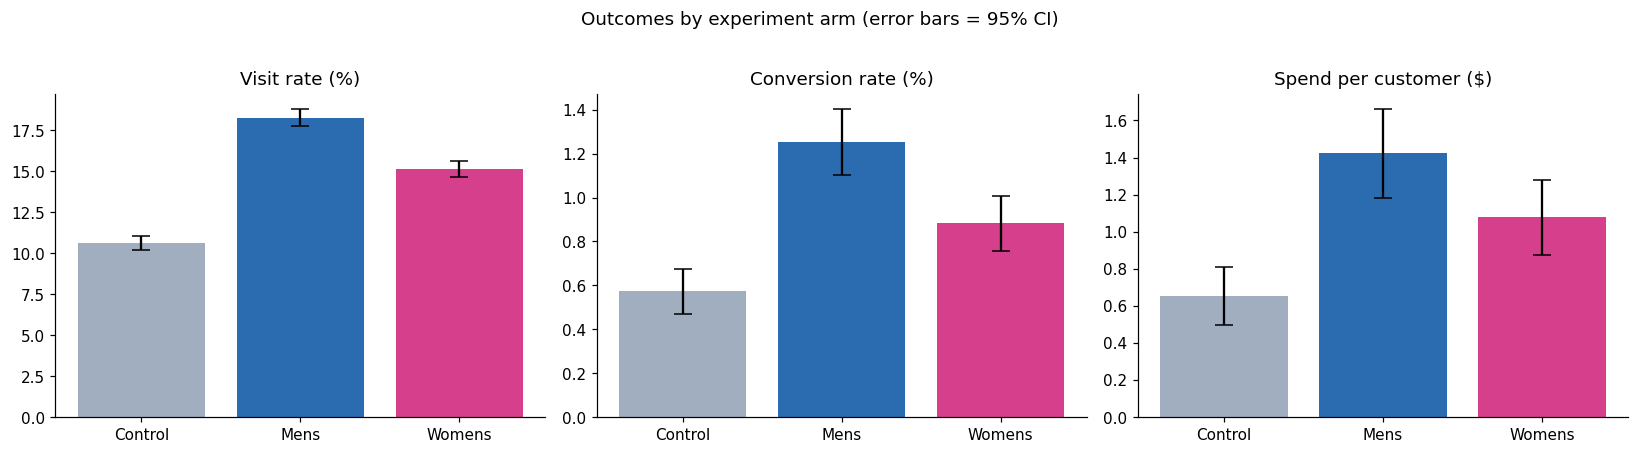

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (outcome, label, scale) in zip(axes, [("visit", "Visit rate (%)", 100),
                                             ("conversion", "Conversion rate (%)", 100),
                                             ("spend", "Spend per customer ($)", 1)]):
    g = df.groupby("arm")[outcome]
    means, ses = g.mean() * scale, g.sem() * scale * 1.96
    ax.bar(means.index, means, yerr=ses, capsize=6, color=[COLORS[a] for a in means.index])
    ax.set(title=label)
fig.suptitle("Outcomes by experiment arm (error bars = 95% CI)", y=1.02)
plt.tight_layout(); plt.show()

**Both emails clearly increased visits, conversions, and spending** compared with no email, and every
difference survives the Holm correction. In the **creative test, the men's email beat the women's email** on all
three outcomes: visits by about 3 percentage points (a 21% relative lift), with weaker evidence for spend
(adjusted p ≈ 0.03, and a wide confidence interval).

## Power Analysis
Conversions are rare (under 1%), so even with ~21,000 customers per group, small conversion effects are hard
to detect. The **minimum detectable effect (MDE)** at 80% power and 5% significance shows what this test can
reliably catch, and how large a future test would need to be.

In [14]:
power = NormalIndPower()
n_per_arm = int(counts.min())

def mde(p0, n, alpha=0.05, pw=0.8):
    h = power.solve_power(nobs1=n, alpha=alpha, power=pw, ratio=1.0)
    p1 = np.sin((h + 2 * np.arcsin(np.sqrt(p0))) / 2) ** 2
    return p1 - p0

rows = []
for outcome in ["visit", "conversion"]:
    p0 = df.loc[df.arm == "Control", outcome].mean()
    m = mde(p0, n_per_arm)
    n_needed = power.solve_power(effect_size=proportion_effectsize(p0 * 1.10, p0), alpha=0.05, power=0.8)
    rows.append({"outcome": outcome, "control_rate": p0, "MDE (absolute)": m, "MDE (relative)": m / p0,
                 "customers per arm to detect a 10% lift": int(np.ceil(n_needed))})
pd.DataFrame(rows).round(4)

,outcome,control_rate,MDE (absolute),MDE (relative),customers per arm to detect a 10% lift
0,visit,0.1062,0.0085,0.0801,13788
1,conversion,0.0057,0.0022,0.3894,285959


With this sample, the test can detect a lift in **visits** of a few percent, but a lift in **conversions** must be
much larger in relative terms to be detected. For future campaigns optimized on conversions, the team would need
substantially more customers per arm, or should use visits as a leading indicator.

## Segmentation test: does the effect differ by customer group?
The average effect can hide large differences between groups. I estimate the visit lift of each email within
customer segments, then test formally with a **regression with interaction terms**.

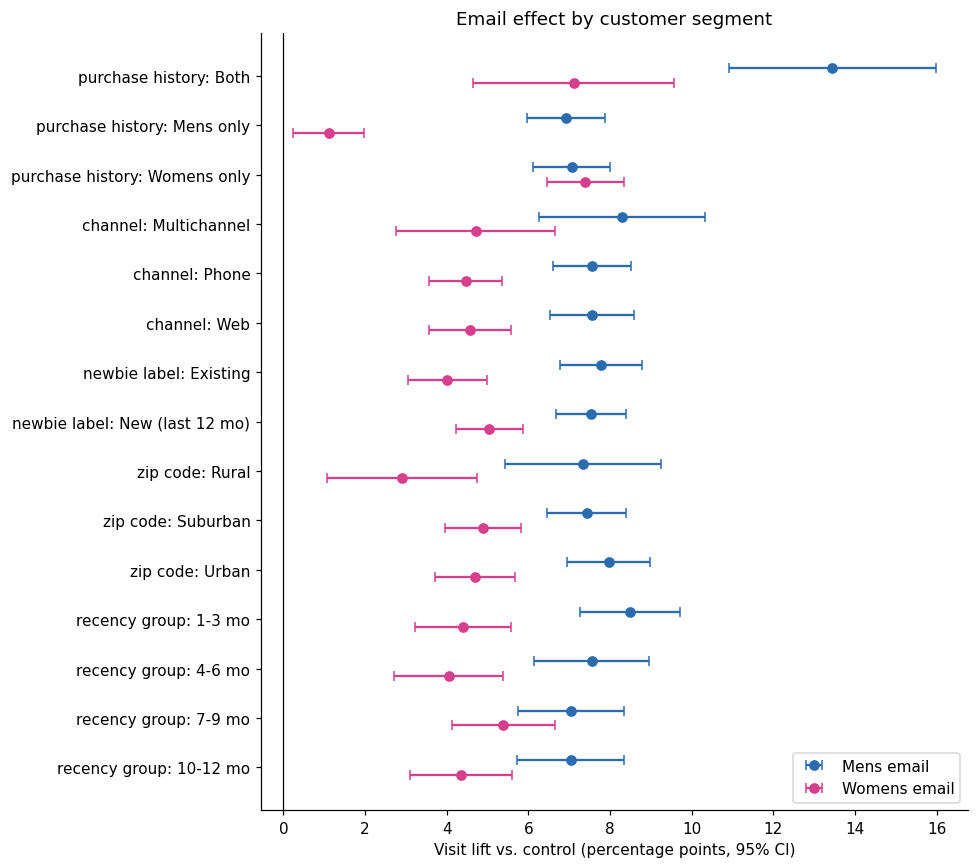

In [15]:
def segment_lifts(seg_col):
    rows = []
    for seg, g in df.groupby(seg_col, observed=True):
        c = g.loc[g.arm == "Control", "visit"]
        for arm in ["Mens", "Womens"]:
            t = g.loc[g.arm == arm, "visit"]
            lo, hi = confint_proportions_2indep(t.sum(), len(t), c.sum(), len(c), method="wald")
            rows.append({"variable": seg_col, "segment": str(seg), "arm": arm, "n": len(g),
                         "lift_pp": (t.mean() - c.mean()) * 100, "ci_low": lo * 100, "ci_high": hi * 100})
    return rows

seg_table = pd.DataFrame(sum([segment_lifts(c) for c in
                              ["purchase_history", "channel", "newbie_label", "zip_code", "recency_group"]], []))

fig, ax = plt.subplots(figsize=(9, 8))
labels = (seg_table.variable.str.replace("_", " ") + ": " + seg_table.segment).unique()[::-1]
ypos = {lab: i for i, lab in enumerate(labels)}
for arm, offset in [("Mens", 0.15), ("Womens", -0.15)]:
    s = seg_table[seg_table.arm == arm]
    y = [ypos[v.replace("_", " ") + ": " + seg] + offset for v, seg in zip(s.variable, s.segment)]
    ax.errorbar(s.lift_pp, y, xerr=[s.lift_pp - s.ci_low, s.ci_high - s.lift_pp], fmt="o",
                color=COLORS[arm], label=f"{arm} email", capsize=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set(xlabel="Visit lift vs. control (percentage points, 95% CI)", title="Email effect by customer segment")
ax.legend(); plt.tight_layout(); plt.show()

In [16]:
# Linear probability model with robust standard errors: coefficients are in percentage points / 100
lpm = smf.ols("visit ~ C(arm, Treatment('Control')) * C(purchase_history, Treatment('Both'))"
              " + recency + log_history + newbie + C(channel) + C(zip_code)", data=df).fit(cov_type="HC1")
inter = lpm.params.filter(like=":").to_frame("coefficient").join(lpm.pvalues.rename("p_value"))
inter.index = inter.index.str.replace("C\\(arm, Treatment\\('Control'\\)\\)\\[T.", "", regex=True) \
                         .str.replace("\\]:C\\(purchase_history, Treatment\\('Both'\\)\\)\\[T.", " x ", regex=True) \
                         .str.replace("]", "", regex=False)
inter.round(4)

,coefficient,p_value
Mens x Mens only,-0.0658,0.0000
Womens x Mens only,-0.0609,0.0000
Mens x Womens only,-0.0644,0.0000
Womens x Womens only,0.0024,0.8573


**The men's email lifts visits in every segment, while the women's email works almost only for customers who
have bought women's products before.** For customers who only bought men's products, the women's email adds about
1 percentage point, versus about 7 points for women's-product buyers. Customers who bought **both** respond
most strongly, especially to the men's email (about 13 points). The interaction terms (relative to "Both")
confirm these differences are statistically significant: this is the evidence for sending different creatives
to different segments.

## Propensity model: who is likely to visit after an email?
I model the likelihood that an emailed customer visits, using only information known before the campaign plus
which email they received. I compare five algorithms:

| Model | Why include it |
|---|---|
| Logistic regression | Interpretable baseline, fit by maximum likelihood |
| Decision tree | Simple if-then rules marketers can read; depth tuned by cross-validation |
| Random forest | Many decorrelated trees averaged to reduce variance |
| Gradient boosting | Trees built sequentially, each correcting the previous trees' errors |
| Neural network (MLP) | A small deep-learning model that learns non-linear combinations of features |

In [17]:
NUM = ["recency", "log_history", "mens", "womens", "newbie", "got_mens_email"]
CAT = ["zip_code", "channel"]

emailed = df[df.arm != "Control"].copy()
emailed["got_mens_email"] = (emailed.arm == "Mens").astype(int)
X, y = emailed[NUM + CAT], emailed["visit"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

def make_pipe(model, scale=False):
    num = StandardScaler() if scale else "passthrough"
    pre = ColumnTransformer([("num", num, NUM), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
    return Pipeline([("prep", pre), ("model", model)])

print(f"Train: {len(X_train):,}  Test: {len(X_test):,}  Visit rate: {y.mean():.3f}")

Train: 32,020  Test: 10,674  Visit rate: 0.167


In [20]:
# Decision tree: tune depth and minimum leaf size with 5-fold cross-validation
tree_search = GridSearchCV(
    make_pipe(DecisionTreeClassifier(random_state=SEED)),
    {"model__max_depth": [3, 4, 5, 6, 8], "model__min_samples_leaf": [50, 200, 500]},
    scoring="roc_auc", cv=5, n_jobs=-1).fit(X_train, y_train)
print("Best decision tree:", tree_search.best_params_, f"CV AUC = {tree_search.best_score_:.3f}")

# Gradient boosting: small tuning grid
gb_search = GridSearchCV(
    make_pipe(HistGradientBoostingClassifier(max_iter=300, early_stopping=True, random_state=SEED)),
    {"model__learning_rate": [0.03, 0.1], "model__max_depth": [3, 6]},
    scoring="roc_auc", cv=3, n_jobs=-1).fit(X_train, y_train)
print("Best gradient boosting:", gb_search.best_params_, f"CV AUC = {gb_search.best_score_:.3f}")

models = {
    "Logistic regression": make_pipe(LogisticRegression(max_iter=1000), scale=True).fit(X_train, y_train),
    "Decision tree": tree_search.best_estimator_,
    "Random forest": make_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=50,
                                                      n_jobs=-1, random_state=SEED)).fit(X_train, y_train),
    "Gradient boosting": gb_search.best_estimator_,
    "Neural network (MLP)": make_pipe(MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, early_stopping=True,
                                                    max_iter=200, random_state=SEED), scale=True).fit(X_train, y_train),
}

Best decision tree: {'model__max_depth': 6, 'model__min_samples_leaf': 200} CV AUC = 0.612
Best gradient boosting: {'model__learning_rate': 0.1, 'model__max_depth': 3} CV AUC = 0.624


Random-guess baselines: ROC AUC = 0.500, PR AUC = 0.167


,model,ROC AUC,PR AUC
0,Logistic regression,0.624,0.241
1,Gradient boosting,0.621,0.238
2,Random forest,0.614,0.231
3,Decision tree,0.609,0.225
4,Neural network (MLP),0.588,0.213


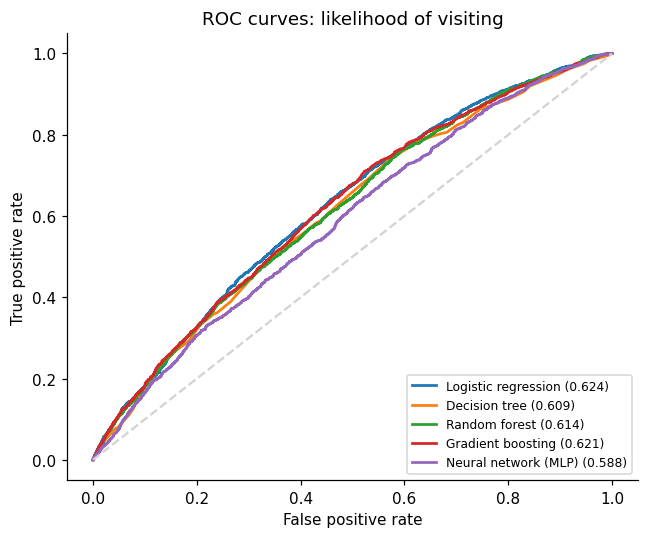

In [19]:
results, probs = [], {}
for name, m in models.items():
    p = m.predict_proba(X_test)[:, 1]; probs[name] = p
    results.append({"model": name, "ROC AUC": roc_auc_score(y_test, p), "PR AUC": average_precision_score(y_test, p)})
results = pd.DataFrame(results).sort_values("ROC AUC", ascending=False).reset_index(drop=True)
print(f"Random-guess baselines: ROC AUC = 0.500, PR AUC = {y_test.mean():.3f}")
display(results.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax.plot(fpr, tpr, lw=1.8, label=f"{name} ({roc_auc_score(y_test, p):.3f})")
ax.plot([0, 1], [0, 1], "--", color="lightgray")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves: likelihood of visiting")
ax.legend(fontsize=8, loc="lower right"); plt.tight_layout(); plt.show()

Visiting is hard to predict from a handful of customer attributes, so every model lands in a similar, modest
range (ROC AUC around 0.6, PR AUC well above the 0.17 random baseline). Notably, the **simple logistic regression
is as good as the complex models**; the random forest, gradient boosting, and neural network add no accuracy
with so few, mostly categorical features. In practice that favors the simpler, more explainable model. The
**decision tree** is still useful because it turns the model into rules a marketer can read.

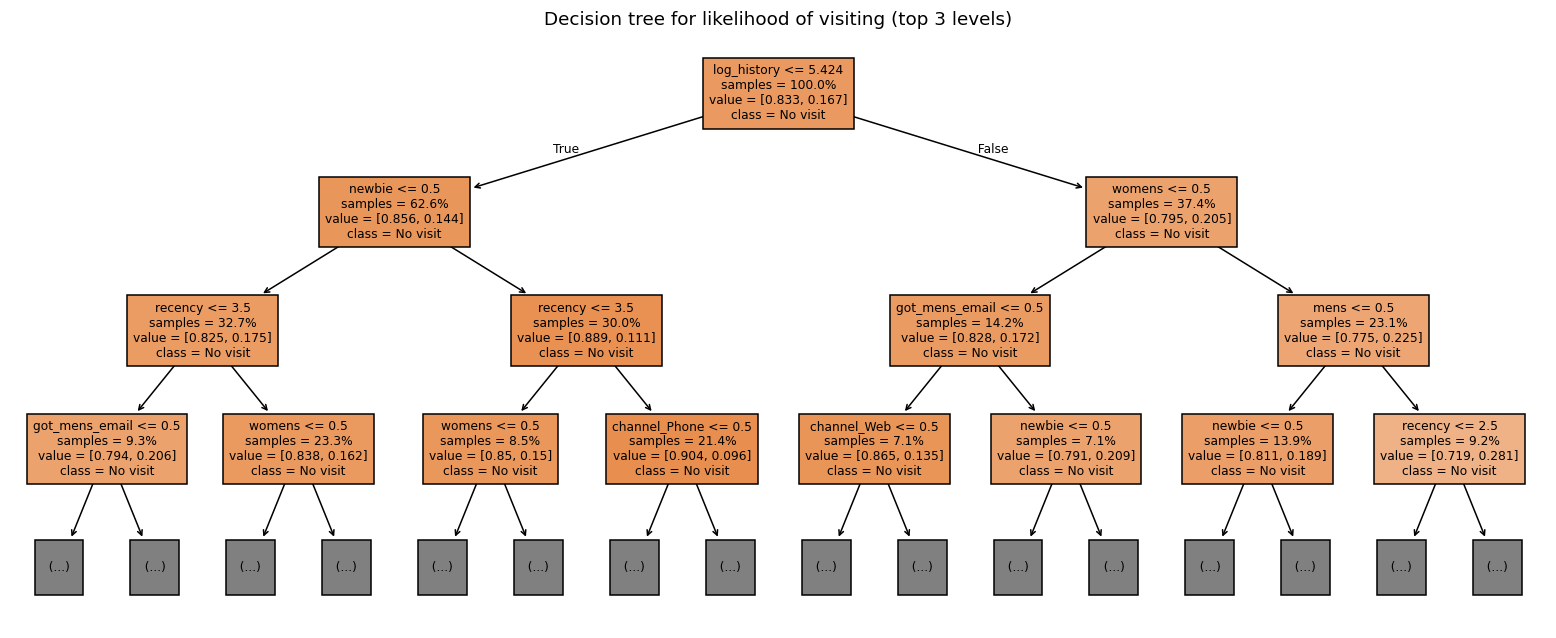

In [21]:
tree = models["Decision tree"].named_steps["model"]
feat_names = models["Decision tree"].named_steps["prep"].get_feature_names_out()
feat_names = [f.split("__")[1] for f in feat_names]

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(tree, feature_names=feat_names, class_names=["No visit", "Visit"], filled=True, impurity=False,
          proportion=True, max_depth=3, fontsize=8, ax=ax)
ax.set_title("Decision tree for likelihood of visiting (top 3 levels)")
plt.show()

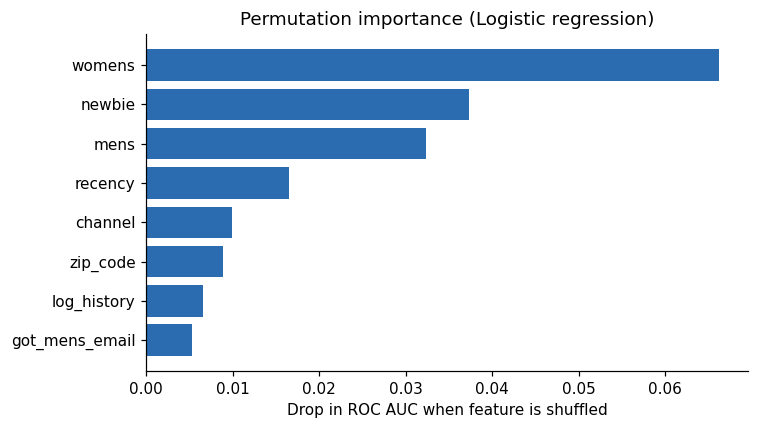

In [22]:
best_name = results.loc[0, "model"]
pi = permutation_importance(models[best_name], X_test, y_test, scoring="roc_auc", n_repeats=5, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp.index, imp.values, color="#2b6cb0")
ax.set(xlabel="Drop in ROC AUC when feature is shuffled", title=f"Permutation importance ({best_name})")
plt.tight_layout(); plt.show()

## Uplift model: who visits *because of* the email?
A propensity model finds customers likely to visit, but many of them would have visited **without** an email.
Marketing budget is best spent on **persuadable** customers: those whose behavior changes because of the email.
This is the **uplift**, or individual treatment effect:

$$\text{uplift}(x) = P(\text{visit} \mid \text{email}, x) - P(\text{visit} \mid \text{no email}, x)$$

Because the experiment is randomized, uplift can be estimated directly. For **each email vs. control**, I compare
three ways of ranking customers:
1. **T-learner:** two gradient-boosting models, one trained on emailed customers and one on controls; uplift is the difference in their predictions.
2. **Uplift decision tree:** a decision tree fit to a *transformed outcome* whose expected value equals the uplift, which gives readable segments.
3. **Propensity ranking (baseline):** rank by likelihood of visiting when emailed, ignoring the control group.

In [23]:
FEATS = ["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]  # trees don't need log(history)
X_all = pd.get_dummies(df[FEATS], columns=["zip_code", "channel"], dtype=float)

def gb():
    return HistGradientBoostingClassifier(learning_rate=0.05, max_depth=3, max_iter=200, random_state=SEED)

LABEL = {"Mens": "Men's", "Womens": "Women's"}
uplift = {}
for arm in ["Mens", "Womens"]:
    d = df[df.arm.isin([arm, "Control"])].copy()
    d["T"] = (d.arm == arm).astype(int)
    tr_idx, te_idx = train_test_split(d.index, test_size=0.3, stratify=d["T"].astype(str) + d.visit.astype(str),
                                      random_state=SEED)
    trn, tst = d.loc[tr_idx], d.loc[te_idx]
    Xtr, Xte = X_all.loc[tr_idx], X_all.loc[te_idx]

    m1 = gb().fit(Xtr[trn["T"] == 1], trn.loc[trn["T"] == 1, "visit"])
    m0 = gb().fit(Xtr[trn["T"] == 0], trn.loc[trn["T"] == 0, "visit"])

    # Uplift tree on the transformed outcome Z = Y * (T - p) / (p * (1 - p)), where E[Z | x] = uplift(x)
    p_t = trn["T"].mean()
    Z = trn["visit"] * (trn["T"] - p_t) / (p_t * (1 - p_t))
    utree = DecisionTreeRegressor(max_depth=3, min_samples_leaf=1500, random_state=SEED).fit(Xtr, Z)

    uplift[arm] = {"test": tst, "X_test": Xte, "tree": utree, "scores": {
        "T-learner": m1.predict_proba(Xte)[:, 1] - m0.predict_proba(Xte)[:, 1],
        "Uplift tree": utree.predict(Xte),
        "Propensity ranking": m1.predict_proba(Xte)[:, 1]}}
    actual = tst.loc[tst["T"] == 1, "visit"].mean() - tst.loc[tst["T"] == 0, "visit"].mean()
    print(f"{LABEL[arm]} email: test customers = {len(tst):,}, average uplift = {actual*100:.2f} pp")

Men's email: test customers = 12,784, average uplift = 7.65 pp
Women's email: test customers = 12,808, average uplift = 4.51 pp


## Evaluating uplift: decile tables and Qini curves
Uplift can't be observed for an individual (each customer either got the email or didn't), so models are
evaluated on groups. I sort test customers by predicted uplift, then compare actual visit rates of emailed and
control customers within each decile. The **Qini curve** shows cumulative *incremental* visits as more customers
are targeted; a better model rises faster above the random-targeting line.

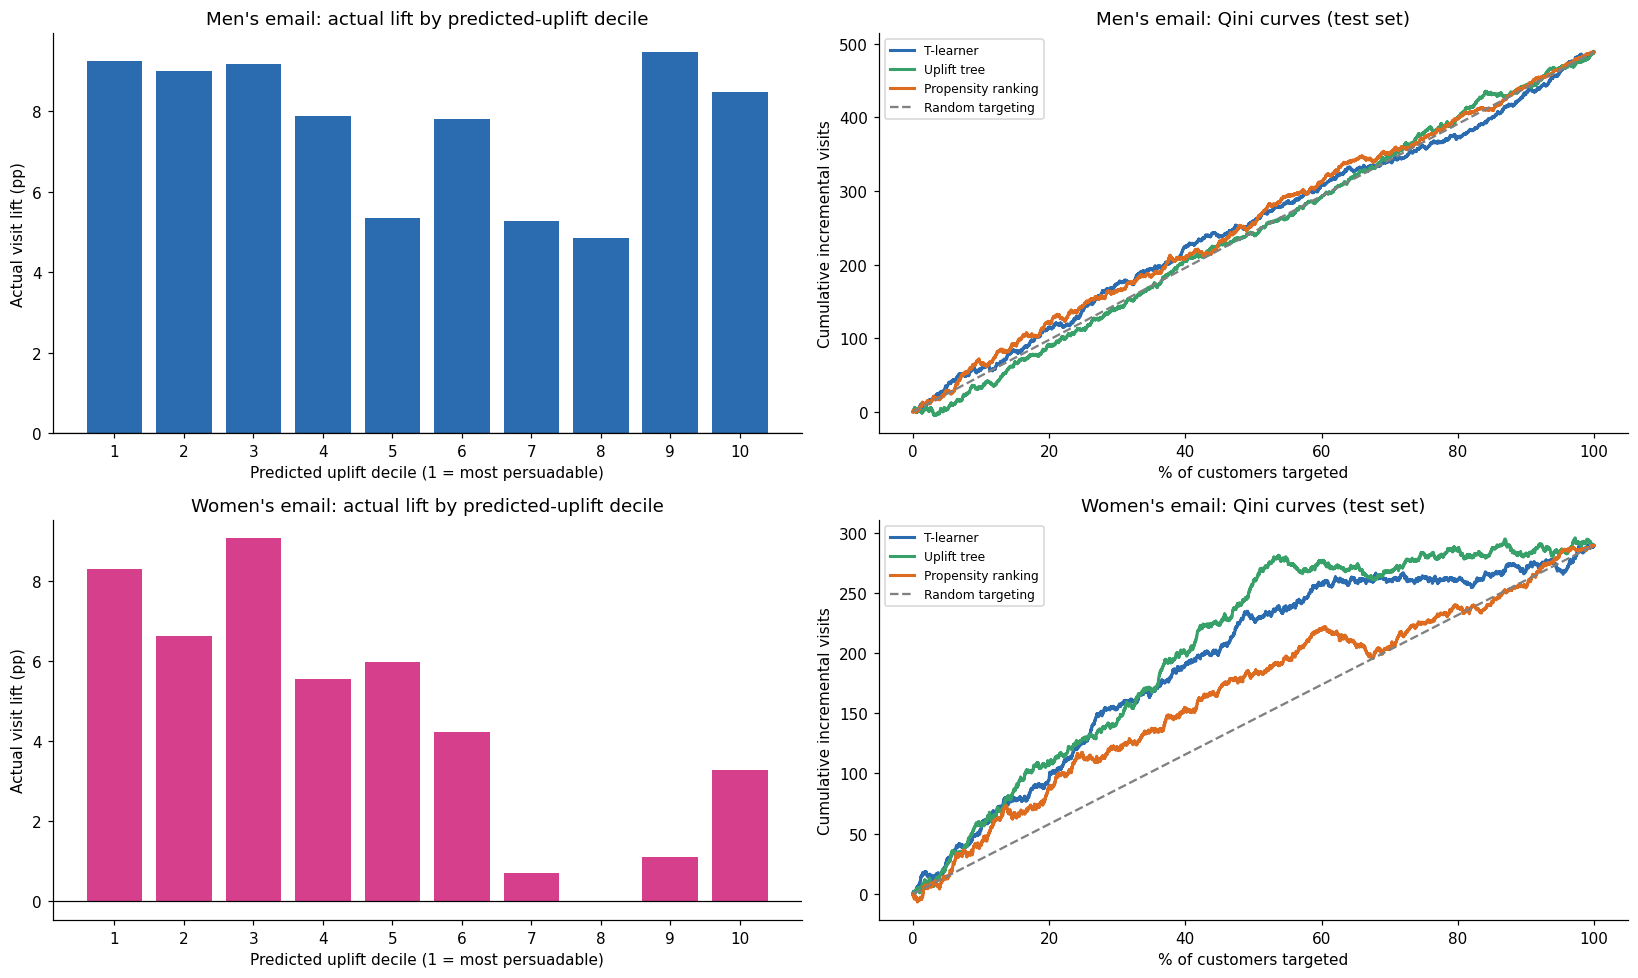

,Propensity ranking (Qini area),T-learner (Qini area),Uplift tree (Qini area)
email,,,
Mens,12.4,7.5,-0.9
Womens,20.3,46.8,58.4


In [24]:
trapz = getattr(np, "trapezoid", None) or np.trapz  # name differs across NumPy versions

def uplift_by_decile(score, data):
    d = data.assign(score=score).sort_values("score", ascending=False)
    d["decile"] = (np.arange(len(d)) * 10 // len(d)) + 1
    out = pd.DataFrame({"visit_rate_email": d[d["T"] == 1].groupby("decile")["visit"].mean(),
                        "visit_rate_control": d[d["T"] == 0].groupby("decile")["visit"].mean()})
    out["actual_uplift_pp"] = (out.visit_rate_email - out.visit_rate_control) * 100
    return out

def qini_curve(score, data):
    d = data.assign(score=score).sort_values("score", ascending=False)
    t, y = d["T"].to_numpy(), d["visit"].to_numpy()
    nt, nc = np.cumsum(t), np.cumsum(1 - t)
    yt, yc = np.cumsum(y * t), np.cumsum(y * (1 - t))
    inc = yt - yc * np.divide(nt, nc, out=np.zeros(len(d)), where=nc > 0)
    return np.r_[0, np.arange(1, len(d) + 1) / len(d)], np.r_[0, inc]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))
qini_table = {}
for row, arm in enumerate(["Mens", "Womens"]):
    u = uplift[arm]
    dec = uplift_by_decile(u["scores"]["T-learner"], u["test"])
    axes[row, 0].bar(dec.index, dec.actual_uplift_pp, color=COLORS[arm])
    axes[row, 0].axhline(0, color="black", lw=0.8)
    axes[row, 0].set(xticks=dec.index, xlabel="Predicted uplift decile (1 = most persuadable)",
                     ylabel="Actual visit lift (pp)", title=f"{LABEL[arm]} email: actual lift by predicted-uplift decile")
    for name, color in [("T-learner", "#2b6cb0"), ("Uplift tree", "#38a169"), ("Propensity ranking", "#dd6b20")]:
        x, q = qini_curve(u["scores"][name], u["test"])
        qini_table[(arm, name)] = trapz(q - x * q[-1], x)
        axes[row, 1].plot(x * 100, q, lw=2, color=color, label=name)
    axes[row, 1].plot([0, 100], [0, q[-1]], "--", color="gray", label="Random targeting")
    axes[row, 1].set(xlabel="% of customers targeted", ylabel="Cumulative incremental visits",
                     title=f"{LABEL[arm]} email: Qini curves (test set)")
    axes[row, 1].legend(fontsize=8)
plt.tight_layout(); plt.show()

pd.Series(qini_table).unstack().round(1).rename_axis("email").add_suffix(" (Qini area)")

The two emails tell different stories:
- **Men's email:** the actual lift is similar across deciles. The email persuades nearly everyone by a similar
  amount, so there is little heterogeneity for an uplift model to exploit, and its ranking is not reliably better
  than propensity ranking.
- **Women's email:** the uplift models concentrate the effect in the top deciles and clearly beat propensity
  ranking. Propensity ranking does poorly because many customers likely to visit (such as men's-product buyers)
  are not persuaded by a women's email.

**The key lesson: likely-to-respond is not the same as likely-to-be-influenced, and uplift modeling pays off
when treatment effects actually vary across customers.**

## Segmentation: turning the uplift tree into marketing segments
The women's email is where targeting matters, so I turn its uplift tree into segments. Each leaf is a segment
defined by simple rules. For each segment I report its size and the **actual** uplift measured on the test set,
with a 95% confidence interval.

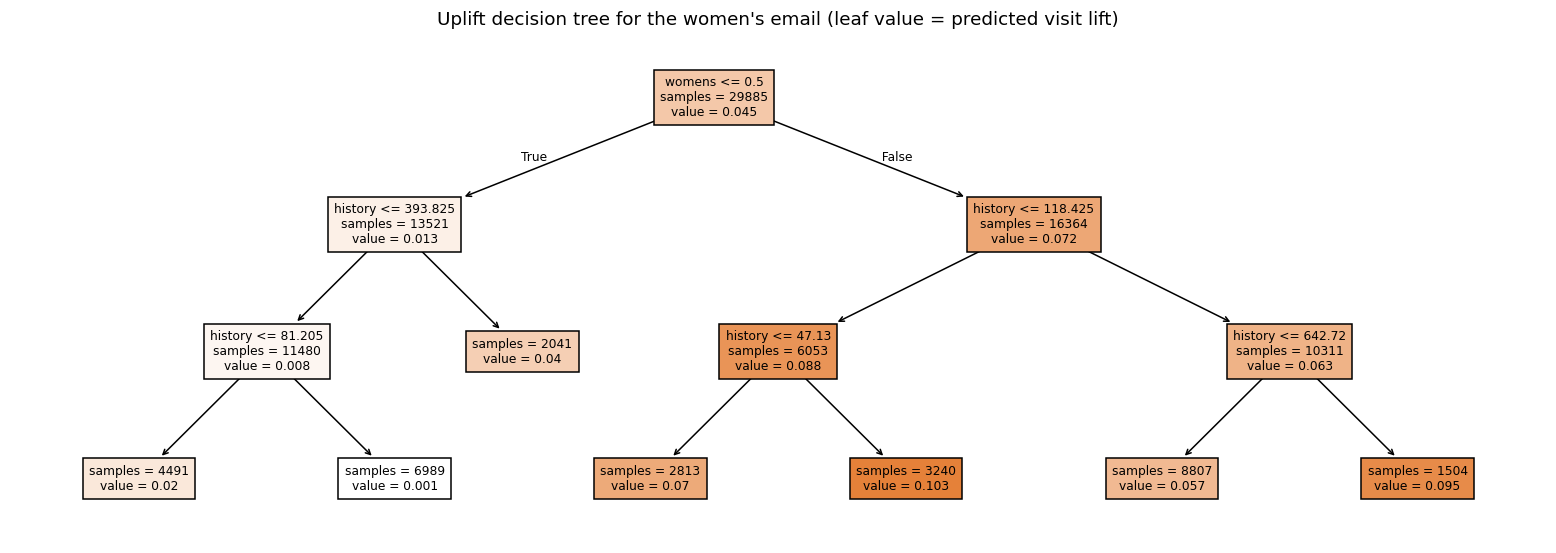

In [25]:
u = uplift["Womens"]
fig, ax = plt.subplots(figsize=(18, 6))
plot_tree(u["tree"], feature_names=list(X_all.columns), filled=True, impurity=False, fontsize=8, ax=ax, precision=3)
ax.set_title("Uplift decision tree for the women's email (leaf value = predicted visit lift)")
plt.show()

In [26]:
def leaf_rules(tree_model, X):
    # Readable rule for each leaf, keeping only the tightest bound per feature
    t, names = tree_model.tree_, list(X.columns)
    binary = {f: set(np.unique(X[f])) <= {0.0, 1.0} for f in names}
    rules = {}
    def recurse(node, bounds):
        if t.children_left[node] == -1:
            parts = []
            for f, (lo, hi) in bounds.items():
                if binary[f]:
                    parts.append(f"{f} = {0 if hi is not None else 1}")
                elif lo is not None and hi is not None:
                    parts.append(f"{lo:,.0f} < {f} <= {hi:,.0f}")
                elif lo is not None:
                    parts.append(f"{f} > {lo:,.0f}")
                else:
                    parts.append(f"{f} <= {hi:,.0f}")
            rules[node] = " AND ".join(parts) if parts else "All customers"
            return
        f, thr = names[t.feature[node]], t.threshold[node]
        lo, hi = bounds.get(f, (None, None))
        left, right = dict(bounds), dict(bounds)
        left[f] = (lo, thr if hi is None else min(hi, thr))
        right[f] = (thr if lo is None else max(lo, thr), hi)
        recurse(t.children_left[node], left); recurse(t.children_right[node], right)
    recurse(0, {})
    return rules

rules = leaf_rules(u["tree"], X_all)
tst_seg = u["test"].assign(leaf=u["tree"].apply(u["X_test"]))
rows = []
for leaf, g in tst_seg.groupby("leaf"):
    t_, c_ = g.loc[g["T"] == 1, "visit"], g.loc[g["T"] == 0, "visit"]
    lo, hi = confint_proportions_2indep(t_.sum(), len(t_), c_.sum(), len(c_), method="wald")
    rows.append({"segment_rule": rules[leaf].replace("history", "past-year spend ($)"), "test_customers": len(g),
                 "share": len(g) / len(tst_seg), "visit_email": t_.mean(), "visit_control": c_.mean(),
                 "uplift_pp": (t_.mean() - c_.mean()) * 100, "ci_low_pp": lo * 100, "ci_high_pp": hi * 100})
segments = pd.DataFrame(rows).sort_values("uplift_pp", ascending=False).reset_index(drop=True)
segments.insert(0, "segment", [f"S{i+1}" for i in range(len(segments))])
with pd.option_context("display.max_colwidth", 120):
    display(segments.round(3))

,segment,segment_rule,test_customers,share,visit_email,visit_control,uplift_pp,ci_low_pp,ci_high_pp
0,S1,womens = 1 AND past-year spend ($) > 643,683,0.053,0.232,0.134,9.824,4.066,15.583
1,S2,womens = 1 AND 47 < past-year spend ($) <= 118,1369,0.107,0.170,0.083,8.775,5.297,12.253
2,S3,womens = 1 AND 118 < past-year spend ($) <= 643,3819,0.298,0.192,0.116,7.610,5.333,9.887
3,S4,womens = 1 AND past-year spend ($) <= 47,1198,0.094,0.155,0.098,5.756,2.008,9.505
4,S5,womens = 0 AND 81 < past-year spend ($) <= 394,2944,0.230,0.122,0.114,0.820,-1.510,3.150
5,S6,womens = 0 AND past-year spend ($) <= 81,1963,0.153,0.088,0.081,0.772,-1.689,3.233
6,S7,womens = 0 AND past-year spend ($) > 394,832,0.065,0.114,0.122,-0.821,-5.204,3.562


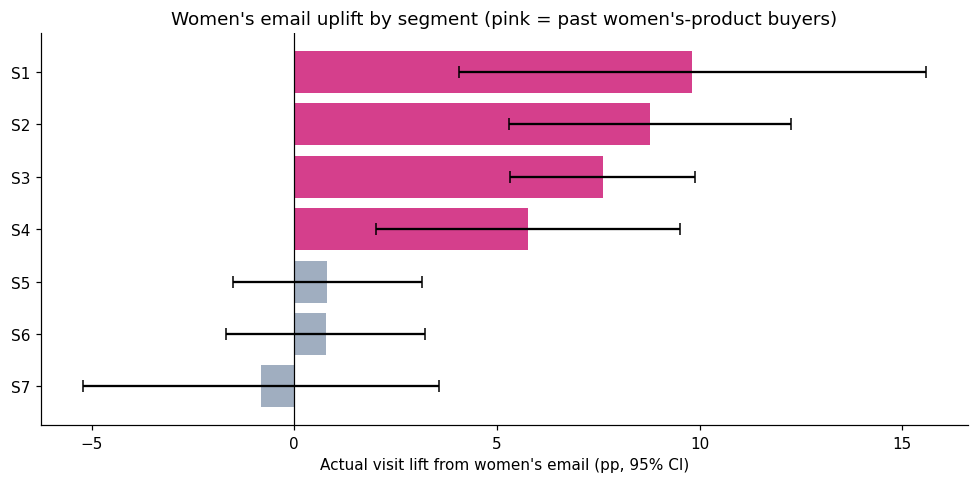

In [27]:
fig, ax = plt.subplots(figsize=(9, 4.5))
seg_colors = ["#d53f8c" if "womens = 1" in r else "#a0aec0" for r in segments.segment_rule]
ax.barh(segments.segment[::-1], segments.uplift_pp[::-1],
        xerr=[(segments.uplift_pp - segments.ci_low_pp)[::-1], (segments.ci_high_pp - segments.uplift_pp)[::-1]],
        color=seg_colors[::-1], capsize=4)
ax.axvline(0, color="black", lw=0.8)
ax.set(xlabel="Actual visit lift from women's email (pp, 95% CI)",
       title="Women's email uplift by segment (pink = past women's-product buyers)")
plt.tight_layout(); plt.show()
segments.to_csv(OUT_DIR / "uplift_segments_womens_email.csv", index=False)

The tree's first split is on whether the customer has bought **women's products** before. Those segments show
clear, positive lifts; segments without a women's purchase history show lifts near zero, with confidence intervals
that include zero. **Practical rule: send the women's email only to past women's-product buyers, and suppress it
for everyone else.**

## Targeting policy: who should get which email?
Hillstrom's original challenge asked: **if you could only email 10,000 of the 64,000 customers, who should get it?**

I train one gradient-boosting model per arm (control, men's, women's) on a training split, predict each test
customer's visit probability under all three options, and pick the email with the highest predicted uplift.
Because assignment in the experiment was random, the value of **any targeting policy** can be estimated without
bias on the test set with **inverse propensity weighting**: average the outcomes of customers whose actual
assignment happened to match the policy's recommendation, weighted by the probability of that assignment.

In [28]:
idx_tr, idx_te = train_test_split(df.index, test_size=0.3, stratify=df.arm + df.visit.astype(str), random_state=SEED)
arms = ["Control", "Mens", "Womens"]
arm_models = {a: gb().fit(X_all.loc[idx_tr][df.loc[idx_tr, "arm"] == a], df.loc[idx_tr][df.loc[idx_tr, "arm"] == a]["visit"])
              for a in arms}
P = pd.DataFrame({a: arm_models[a].predict_proba(X_all.loc[idx_te])[:, 1] for a in arms}, index=idx_te)
P["uplift_mens"], P["uplift_womens"] = P.Mens - P.Control, P.Womens - P.Control
P["best_email"] = np.where(P.uplift_mens >= P.uplift_womens, "Mens", "Womens")
P["best_uplift"] = P[["uplift_mens", "uplift_womens"]].max(axis=1)

test = df.loc[idx_te]
assign_prob = test.arm.map(test.arm.value_counts(normalize=True))

def policy_value(recommended, outcome="visit"):
    match = (test.arm == recommended).astype(float)
    return np.mean(match * test[outcome] / assign_prob)

K = round(10_000 / len(df) * len(test))  # same share of customers as 10,000 out of 64,000
top_k = P.best_uplift.rank(ascending=False) <= K
rng = np.random.default_rng(SEED)
random_k = pd.Series(False, index=idx_te); random_k[rng.choice(idx_te, K, replace=False)] = True
top_prop = P.Mens.rank(ascending=False) <= K

policies = {
    "No email": pd.Series("Control", index=idx_te),
    "Men's email to everyone": pd.Series("Mens", index=idx_te),
    "Women's email to everyone": pd.Series("Womens", index=idx_te),
    "Best email per customer (model)": P.best_email,
    "10k budget: random customers, men's email": np.where(random_k, "Mens", "Control"),
    "10k budget: highest propensity, men's email": np.where(top_prop, "Mens", "Control"),
    "10k budget: highest uplift, best email (model)": np.where(top_k, P.best_email, "Control"),
}
base = policy_value(policies["No email"])
policy_table = pd.DataFrame([{"policy": k, "share_emailed": np.mean(pd.Series(v) != "Control"),
                              "visit_rate": policy_value(pd.Series(v, index=idx_te)),
                              "spend_per_customer": policy_value(pd.Series(v, index=idx_te), "spend")}
                             for k, v in policies.items()])
policy_table["incremental_visits_per_1k"] = (policy_table.visit_rate - base) * 1000
policy_table.round(4)

,policy,share_emailed,visit_rate,spend_per_customer,incremental_visits_per_1k
0,No email,0.0000,0.1062,0.7925,0.0000
1,Men's email to everyone,1.0000,0.1827,1.5107,76.5019
2,Women's email to everyone,1.0000,0.1513,1.0779,45.1139
3,Best email per customer (model),1.0000,0.1843,1.4571,78.0677
4,"10k budget: random customers, men's email",0.1562,0.1181,0.9523,11.8899
5,"10k budget: highest propensity, men's email",0.1562,0.1205,1.0342,14.2365
6,"10k budget: highest uplift, best email (model)",0.1562,0.1167,0.8944,10.4590


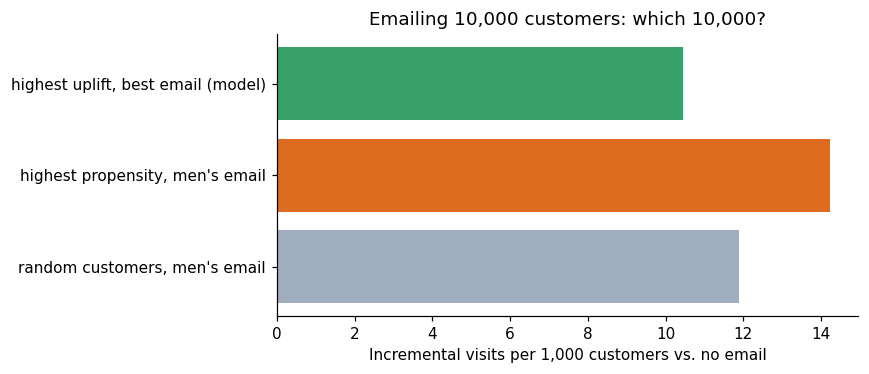

In [29]:
budget = policy_table[policy_table.policy.str.startswith("10k")]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(budget.policy.str.replace("10k budget: ", ""), budget.incremental_visits_per_1k,
        color=["#a0aec0", "#dd6b20", "#38a169"])
ax.set(xlabel="Incremental visits per 1,000 customers vs. no email",
       title="Emailing 10,000 customers: which 10,000?")
plt.tight_layout(); plt.show()

In [30]:
# How certain are these differences? Bootstrap the test set and recompute each policy's value.
pol_arrays = {k: np.asarray(pd.Series(v, index=idx_te)) for k, v in policies.items()}
y_te, arm_te, w_te = test.visit.to_numpy(), test.arm.to_numpy(), (1 / assign_prob).to_numpy()
rng = np.random.default_rng(SEED)
boot = {k: [] for k in ["Uplift - random", "Propensity - random", "Best email - men's to all"]}
for _ in range(1000):
    i = rng.integers(0, len(test), len(test))
    val = lambda pol: np.mean((arm_te[i] == pol_arrays[pol][i]) * y_te[i] * w_te[i])
    boot["Uplift - random"].append(val("10k budget: highest uplift, best email (model)")
                                   - val("10k budget: random customers, men's email"))
    boot["Propensity - random"].append(val("10k budget: highest propensity, men's email")
                                       - val("10k budget: random customers, men's email"))
    boot["Best email - men's to all"].append(val("Best email per customer (model)") - val("Men's email to everyone"))
pd.DataFrame({k: {"difference (visits per 1k)": np.mean(v) * 1000,
                  "95% CI low": np.percentile(v, 2.5) * 1000, "95% CI high": np.percentile(v, 97.5) * 1000}
              for k, v in boot.items()}).T.round(2)

,difference (visits per 1k),95% CI low,95% CI high
Uplift - random,-1.49,-9.10,5.61
Propensity - random,2.02,-5.32,9.55
Best email - men's to all,1.68,-5.46,8.75


**Interpreting the policy results honestly:**
- **Emailing beats not emailing by a wide margin**, and the **men's email to everyone** captures almost all of
  the available gain. Choosing the best email per customer adds very little on top, and the bootstrap interval
  shows that small difference is not reliably different from zero.
- **With a 10,000-customer budget**, targeted lists (by uplift or by propensity) do a bit better than a random
  list, but the bootstrap intervals are wide. Because the men's email persuades customers fairly uniformly,
  *which* 10,000 customers receive it matters less than one might expect.

This is a useful result in itself: sophisticated targeting is only worth its complexity when treatment effects
truly vary. Here, the clear wins are **(1) send the men's email broadly** and **(2) restrict the women's email to
past women's-product buyers.**

## Dashboard-ready outputs
For stakeholders to explore results themselves, I export tidy tables that load directly into
**Tableau** or **Power BI**: experiment results, segment-level lifts, uplift segments, and customer-level
recommendations.

In [31]:
tests.to_csv(OUT_DIR / "ab_test_results.csv", index=False)
seg_table.to_csv(OUT_DIR / "segment_lifts.csv", index=False)
policy_table.to_csv(OUT_DIR / "policy_comparison.csv", index=False)
(df.loc[idx_te, ["recency", "history", "purchase_history", "zip_code", "channel", "newbie", "arm", "visit"]]
   .join(P[["uplift_mens", "uplift_womens", "best_email", "best_uplift"]])
   .assign(target_in_10k_campaign=top_k)
   .to_csv(OUT_DIR / "customer_recommendations.csv", index_label="row_id"))
print("Saved:", sorted(p.name for p in OUT_DIR.glob("*.csv")))

Saved: ['ab_test_results.csv', 'customer_recommendations.csv', 'policy_comparison.csv', 'segment_lifts.csv', 'uplift_segments_womens_email.csv']


## Conclusions

**Experiment results**
- The experiment was valid: group sizes matched the planned 1/3 split, and all customer characteristics were balanced.
- Both emails significantly increased visits, conversions, and spending relative to no email.
- In the creative test, the **men's email outperformed the women's email**, most clearly on visits.

**Who to target**
- The men's email lifts visits in every segment, so it can be sent broadly.
- The women's email works almost only for customers who previously bought women's products; for others its
  effect is near zero. Uplift modeling identifies these persuadable customers much better than a propensity model.
- Personalizing the email choice adds little beyond sending the men's email to everyone, and with a fixed
  budget, targeting improves on random selection only modestly, because the men's email effect is fairly uniform.

**Caveats**
- Conversions are rare, so the test has limited power for conversion and spend; visits are the most reliable outcome.
- Individual uplift estimates are noisy; segment-level results with confidence intervals should guide decisions.
- Results come from one retailer's 2008 campaign and should be re-validated with a new holdout test before rollout.